In [10]:
# Load Data and Define X, y

from pathlib import Path
import pandas as pd

base_dir = Path("/content/drive/My Drive/gdsc-drug-response")
data_path = base_dir / "processed" / "gdsc_fulvestrant_ln_ic50_modelready.csv"

df = pd.read_csv(data_path)

response_col = "LN_IC50"
drug_col     = "DRUG_NAME"
cell_col     = "CELL_LINE_NAME"
non_feature_cols = [drug_col, cell_col, response_col]

# Take all numeric columns, then remove the target
numeric_cols = df.select_dtypes(include=["number"]).columns.tolist()
feature_cols = [c for c in numeric_cols if c != response_col]

X = df[feature_cols].values
y = df[response_col].values
X.shape, y.shape

((1680, 4), (1680,))

In [11]:
# Train/Test Split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)
X_train.shape, X_test.shape

((1344, 4), (336, 4))

In [12]:
# Scale Features and Fit Ridge

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

ridge = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)   # you can tune alpha later
)

ridge.fit(X_train, y_train)

Pipeline(steps=[('standardscaler', StandardScaler()), ('ridge', Ridge())])

In [15]:
# Evaluate on Train and Test

from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

y_train_pred = ridge.predict(X_train)
y_test_pred  = ridge.predict(X_test)

r2_train = r2_score(y_train, y_train_pred)
r2_test  = r2_score(y_test, y_test_pred)

rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))
rmse_test  = np.sqrt(mean_squared_error(y_test, y_test_pred))

r2_train, r2_test, rmse_train, rmse_test

(0.9931056761626309,
 0.9935006664994922,
 np.float64(0.10530852718247516),
 np.float64(0.09896938401330962))

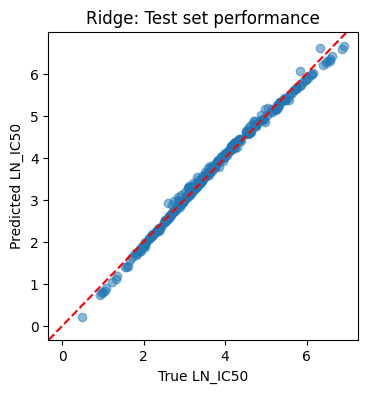

In [16]:
import matplotlib.pyplot as plt
plt.figure(figsize=(4,4))
plt.scatter(y_test, y_test_pred, alpha=0.5)
plt.xlabel("True LN_IC50")
plt.ylabel("Predicted LN_IC50")
plt.axline((0,0), slope=1, color="red", linestyle="--")
plt.title("Ridge: Test set performance")
plt.show()

In [17]:
print(feature_cols)

['DRUG_ID', 'AUC', 'Z_SCORE', 'COSMIC_ID']
